# Binary Classification of Iris Dataset using Logistic Regression
**Date:** 20-08-2026  
**Aim:** Implement a binary classification Machine Learning model using Logistic Regression on `Iris-setosa` and `Iris-versicolor` classes, and evaluate performance using key classification metrics.  
**Tools / Libraries:** `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    cohen_kappa_score, 
    precision_score, 
    recall_score
)

# 1. Load the Iris dataset
df = pd.read_csv('iris_dataset.csv')

# 2. Filter dataset for binary classification (setosa and versicolor only)
binary_df = df[df['species'].isin(['setosa', 'versicolor'])].copy()

# 3. Define Features (X) and Target (y)
feature_cols = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
X = binary_df[feature_cols]

# Map species to binary labels: setosa = 0, versicolor = 1
y = binary_df['species'].map({'setosa': 0, 'versicolor': 1})

# 4. Split data into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total Binary Samples: {len(binary_df)}")
print(f"Training Samples: {len(X_train)} | Testing Samples: {len(X_test)}")

Total Binary Samples: 100
Training Samples: 80 | Testing Samples: 20


In [2]:
# Initialize and fit Logistic Regression
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Make predictions on test set
y_pred = model.predict(X_test)

print("Logistic Regression model trained and predictions generated successfully.")

Logistic Regression model trained and predictions generated successfully.


In [3]:
# Compute Confusion Matrix components (TN, FP, FN, TP)
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
kappa = cohen_kappa_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred)  # Sensitivity = True Positive Rate / Recall
precision = precision_score(y_test, y_pred)
recall = sensitivity                        # Recall is identical to Sensitivity
f_fall = FP / (FP + TN) if (FP + TN) > 0 else 0.0  # Fall-out / False Positive Rate

# Display Performance Evaluation Results
print("=" * 50)
print("       LOGISTIC REGRESSION EVALUATION METRICS       ")
print("=" * 50)
print(f"1. Confusion Matrix:\n   TN: {TN} | FP: {FP}\n   FN: {FN} | TP: {TP}\n")
print(f"2. Accuracy        : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"3. Error Rate      : {error_rate:.4f} ({error_rate * 100:.2f}%)")
print(f"4. Kappa Score     : {kappa:.4f}")
print(f"5. Sensitivity     : {sensitivity:.4f}")
print(f"6. Precision       : {precision:.4f}")
print(f"7. Recall          : {recall:.4f}")
print(f"8. Fall-out (F-fall): {f_fall:.4f}")
print("=" * 50)

       LOGISTIC REGRESSION EVALUATION METRICS       
1. Confusion Matrix:
   TN: 10 | FP: 0
   FN: 0 | TP: 10

2. Accuracy        : 1.0000 (100.00%)
3. Error Rate      : 0.0000 (0.00%)
4. Kappa Score     : 1.0000
5. Sensitivity     : 1.0000
6. Precision       : 1.0000
7. Recall          : 1.0000
8. Fall-out (F-fall): 0.0000


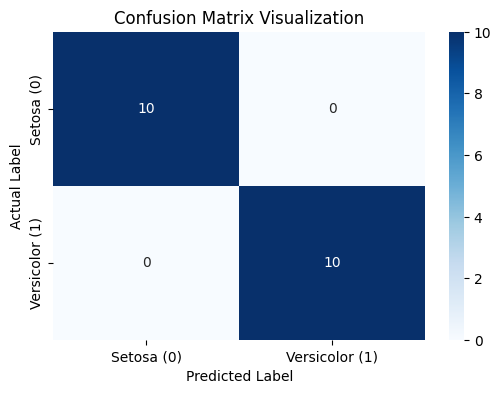

In [4]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Setosa (0)', 'Versicolor (1)'],
    yticklabels=['Setosa (0)', 'Versicolor (1)']
)
plt.title('Confusion Matrix Visualization')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()